In [1]:
# %pip install torch torchvision torchaudio

# need to run on your laptop to install torch so we can import it

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import Dataset, DataLoader

In [3]:
df = pd.read_csv("AirportFootfalls_data.csv")
df

,index,Passenger Traffic (x100 passengers)
0,1,321.3
1,2,324.9
2,3,342.5
3,4,344.5
4,5,343.2
...,...,...
2995,2996,900.8
2996,2997,901.3
2997,2998,904.6
2998,2999,903.6


<function matplotlib.pyplot.show(close=None, block=None)>

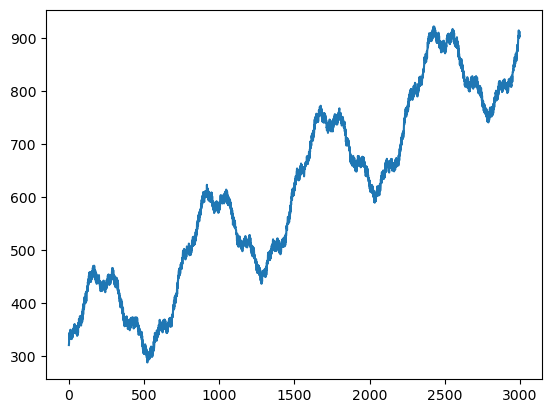

In [4]:
plt.plot(df['Passenger Traffic (x100 passengers)'])
plt.show

In [5]:
series = df['Passenger Traffic (x100 passengers)'].values #so don't have to worry about index that may cause bugs

n = len(series)
train_end = int(n*0.7) 
validation_end = int(n*0.85)

train_data = series[:train_end]
validation_data = series[train_end:validation_end]
test_data = series [validation_end:]
#70-15-15 split

print(f"Train shape: {train_data.shape}")
print(f"Validation shape: {validation_data.shape}")
print(f"Test shape: {test_data.shape}")

Train shape: (2100,)
Validation shape: (450,)
Test shape: (450,)


In [6]:
#reshape 1D array (series) to 2D array so we can use for scikit learn

train_2d = train_data.reshape(-1,1)
validation_2d = validation_data.reshape(-1,1)
test_2d = test_data.reshape(-1,1)

#need scaler to squish output values between 0 and 1 so gradient descent works as it should later - no exploding gradient
scaler = MinMaxScaler(feature_range=(0,1)) #scale range is 0 to 1

train_scaled = scaler.fit_transform(train_2d) 
validation_scaled = scaler.transform(validation_2d) #didn't use fit here becuase we shouldn't see/know "future" data
test_scaled = scaler.transform(test_2d)


In [7]:
#Feature Engineering to feed values in DL model
# input output pairs - like table in #2
# using lag / window size = 4 becuase this is what the example table looked like
# Sample output: X = [x1, x2, x3, x4], y = x5

class TSDataset(Dataset):
    def __init__(self, data, window_size):
        self.X = []
        self.y = []
        flatten_data = data.flatten() #make sure data is 1D to make index slicing easier

        for i in range(len(flatten_data) - window_size):
            self.X.append(flatten_data[i:i+window_size])
            self.y.append(flatten_data[i+window_size])
        #this loops makes 
        # 1) X which is 4 consecutive data points like [x_t, x_t+1, x_t+2, x_t+3] and 
        # 2) y the target value whcih is the value immediately after X like [x+t+4]

        #converting to PyTorch Tensors. Since doing a regression use float32
        self.X = torch.tensor(np.array(self.X), dtype=torch.float32)
        self.y = torch.tensor(np.array(self.y), dtype=torch.float32).unsqueeze(1) #unsqueen to turn y 2D like how X is

    #so pytorch now how my X,y pairs there are
    def __len__(self):
        return len(self.X)

    #so pytorch can grab a singular X,y pair
    def __getitem__(self, index):
        return self.X[index], self.y[index]

#creates X,y pair for full dataset
#initalize sliding window dataset using lag=4
train_dataset = TSDataset(train_scaled, 4)
validation_dataset = TSDataset(validation_scaled, 4)
test_dataset = TSDataset(test_scaled, 4)

#create pytorch dataloaders; batch size = 32 (arbitary), since time series we use shuffle = false (keep in chronological order)
train_loader = DataLoader(train_dataset, 32, shuffle=False)
validation_loader = DataLoader(validation_dataset, 32, shuffle=False)
test_loader = DataLoader(test_dataset, 32, shuffle=False)

print(f"Sample Batch X shape: {train_dataset.X.shape}")
print(f"Sample Batch y shape: {train_dataset.y.shape}")

Sample Batch X shape: torch.Size([2096, 4])
Sample Batch y shape: torch.Size([2096, 1])


In [8]:
#making the feed forward nueral network architechture
#only 2 layers but can easily add more, hidden_dimi = # of nuerons
class TSFFNN(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2, output_dim):
        super(TSFFNN, self).__init__()

        #input layer -> first hidden layer
        self.fc1 = nn.Linear(input_dim, hidden_dim1)
        self.relu1 = nn.ReLU() #relu for non linear activation function

        #firsrt hidden layer -> second hidden layer
        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.relu2 = nn.ReLU()

        #second hidden layer -> outputlayer
        self.fc3 = nn.Linear(hidden_dim2, output_dim)

    #passing input through differnt layers + relu 
    def forward(self, x):
        out = self.relu1(self.fc1(x))
        out = self.relu2(self.fc2(out))
        out = self.fc3(out)
        return out

#Model
model = TSFFNN(4,64,32,1)
loss_func = nn.MSELoss() #use MSE to build loss function bc really good for regression and what was suggested in project
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #Adam optimaizer automatically adjusts lr (learning rate) per parameter

#Training w/ epochs
epochs = 1000
train_losses = []
validation_losses = []

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad() #reset gradient to 0
        predictions = model(batch_X) #forward pass
        loss = loss_func(predictions, batch_y) #compute loss
        loss.backward() #back prop
        optimizer.step() #update weights
        running_train_loss += loss.item() * batch_X.size(0) #update overall training loss

    epoch_train_loss = running_train_loss/len(train_loader.dataset)
    train_losses.append(epoch_train_loss)


    #Validation
    model.eval()
    running_validation_loss = 0.0

    with torch.no_grad():
        for batch_X, batch_y in validation_loader:
            predictions = model(batch_X)
            loss = loss_func(predictions, batch_y)
            running_validation_loss += loss.item() * batch_X.size(0)

    epoch_validation_loss = running_validation_loss/len(validation_loader.dataset)
    validation_losses.append(epoch_validation_loss)

print(train_losses)
print(validation_losses)

[0.01623875698926041, 0.01332825566717523, 0.005887658430133655, 0.002279879401334853, 0.0010135574757302792, 0.0008708002885096202, 0.000965494031681082, 0.0010533216554904357, 0.0011318289276695888, 0.001189283533579446, 0.0012408390069466604, 0.0012881020136232637, 0.00133789841393151, 0.0013926509957834332, 0.0014082971435548553, 0.001425280365008747, 0.0014321283105839014, 0.001429093956773148, 0.0014142405904006598, 0.0013924749251072943, 0.0013666080664963291, 0.0013431509578367695, 0.001315994836249609, 0.0012887089277412351, 0.00126055697754971, 0.001235290087905236, 0.0012151911467174247, 0.001193958263198191, 0.0011718284943228133, 0.0011513485460038267, 0.00113365555182988, 0.0011162933700105695, 0.0011044236458571386, 0.0010931925021777577, 0.0010819165823663024, 0.0010735641783152223, 0.001065908887762157, 0.0010590434285682334, 0.0010567653983323089, 0.0010541301181331945, 0.001053718801473182, 0.00105340619234258, 0.001053208985676072, 0.001053222888975781, 0.0010543238

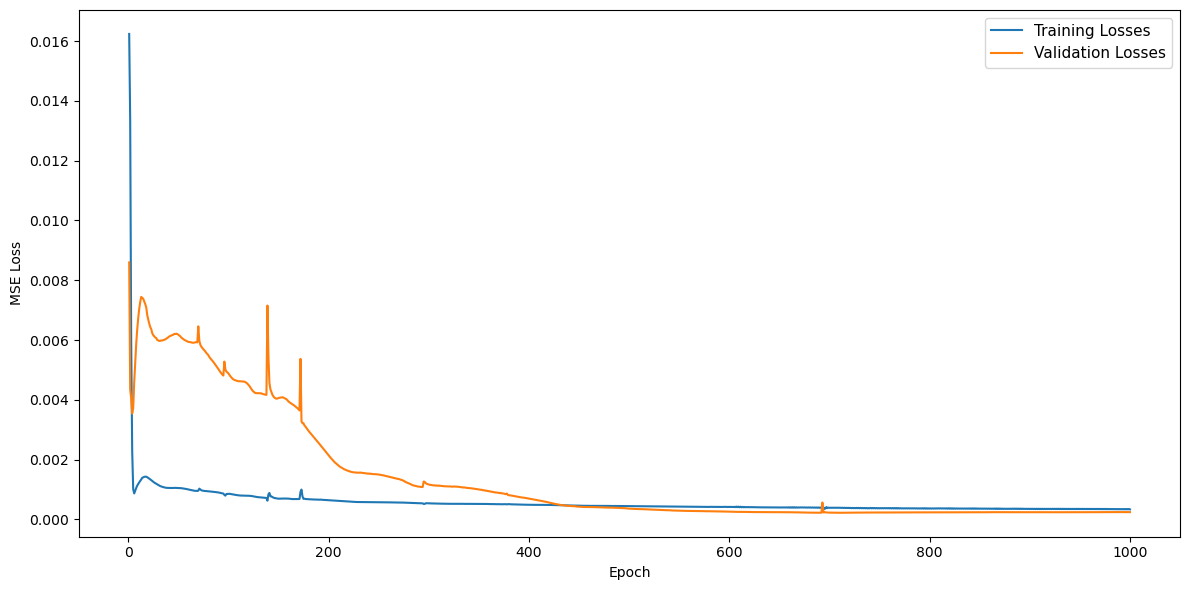

In [9]:
#plot of training vs validation loss curve

plt.figure(figsize=(12,6))
plt.plot(range(1, epochs+1), train_losses, label="Training Losses")
plt.plot(range(1, epochs+1), validation_losses, label = "Validation Losses")
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

#ughhh idk why its osicallating like tht it should gradually descend to 0 ugghh will look back at model later

In [10]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

data = df['Passenger Traffic (x100 passengers)'].values

train_size = int(len(data) * 0.7)
val_size = int(len(data) * 0.15)

train = data[:train_size]
val = data[train_size:train_size + val_size]
test = data[train_size + val_size:]

# set to previous value
naive_predictions = test[:-1]
y_actual = test[1:]

naive_mse = mean_squared_error(y_actual, naive_predictions) #i saw u used nn.MSELoss() but i have no clue what that is
naive_rmse = np.sqrt(naive_mse)
naive_mae = mean_absolute_error(y_actual, naive_predictions)

print(naive_mse, naive_rmse, naive_mae)

68.47374164810691 8.274886201520049 6.783741648106905


In [11]:
#evaluate the dl model

model.eval()

dl_predictions = []
dl_actual = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        predictions = model(batch_X)

        dl_predictions.extend(predictions.numpy())
        dl_actual.extend(batch_y.numpy())

dl_predictions = np.array(dl_predictions).reshape(-1, 1)
dl_actual = np.array(dl_actual).reshape(-1, 1)

# convert scaled values back to original passenger traffic units
dl_predictions = scaler.inverse_transform(dl_predictions)
dl_actual = scaler.inverse_transform(dl_actual)

dl_mse = mean_squared_error(dl_actual, dl_predictions)
dl_rmse = np.sqrt(dl_mse)
dl_mae = mean_absolute_error(dl_actual, dl_predictions)

print(dl_mse, dl_rmse, dl_mae)

53.26249694824219 7.2981159862146745 5.911518096923828
